# 🛡️ Deepfake Detection Pipeline: Video Classification with CNN-LSTM

## Problem Statement: 
Rapid advancements in generative AI and deep learning have made hyper-realistic synthetic media (deepfakes) easily accessible, posing severe security and misinformation risks. This notebook builds an end-to-end deep learning pipeline to automatically classify video files as either **REAL** or **FAKE** by extracting spatial features from individual frames via a **Convolutional Neural Network** and capturing temporal anomalies across sequences using a **Long Short-Term Memory network**.

## ⚙️ Pipeline Steps & Workflow
1. **Environment & Hardware Setup:** Configures reproducibility seeds and checks for GPU acceleration support via TensorFlow.

2. **Metadata Parsing:** Loads video dataset records from metadata.json, maps binary labels, and filters out missing files.

3. **Face Extraction & Preprocessing:** Employs OpenCV Haar Cascades to detect facial regions across video frames, resizing and normalizing pixel values.

4. **Data Augmentation & Splitting:** Applies sequence-level random horizontal flips and brightness scaling to expand training robustness, followed by a stratified train-validation split.

5. **Hybrid Model Architecture:** Combines a frozen MobileNetV2 spatial feature extractor with TimeDistributed layers, an LSTM temporal sequence tracker, and L2 regularized dense classification layers.

6. **Training & Optimization:** Trains the model using Binary Cross-Entropy loss, the Adam optimizer, early stopping, and learning rate scheduling callbacks.

7. **Evaluation & Metrics:** Generates quantitative performance metrics including accuracy, classification reports, confusion matrices, and ROC-AUC curves.

## 🛠️ Technologies & Libraries
**Frameworks & Tools:** Python, TensorFlow, Keras, OpenCV, Scikit-learn, Pandas, NumPy, TQDM, Matplotlib

## 1. Import Libraries and Hardware Configuration

In [2]:
import os
import time
import json
import random
from PIL import Image

# Data processing and computation
import numpy as np
import pandas as pd
from tqdm import tqdm

# Video processing
import cv2 

# Tensorflow modules
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models

# scikit-learn modules
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve


# === ENVIRONMENT SETUP ===

# Set a random seed for reproducibility across runs
SEED = 42
random.seed(SEED)
np.random.seed(SEED)


 # === CONFIGURATION & HYPERPARAMETERS ===

IMG_SIZE        = 224       # Standard image size for CNN backbones
SEQUENCE_LENGTH = 20        # Number of frames extracted per video clip
BATCH_SIZE      = 4         # Batch size used in training
EPOCHS          = 10        # No. of iterations
CHANNELS        = 3         # 

# Determine the device (GPU or CPU)
print("Using Tensorflow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print("GPU detected: Ready for high-speed training!")
else:
    print("No GPU detected. Training on CPU will be slow.")


Using Tensorflow version: 2.1.0-rc0
GPU detected: Ready for high-speed training!


## 2. Reading and Preparing Metadata

In [3]:
# Defining Base Path 
DATA_DIR = '../input/deepfake-detection-challenge/train_sample_videos/'
METADATA_PATH = os.path.join(DATA_DIR, 'metadata.json')

# 1. Load metadata from the JSON file
try:
    with open(METADATA_PATH, 'r') as f:
        metadata = json.load(f)
except FileNotFoundError:
    print(f"Error: Metadata file not found at {METADATA_PATH}. Check your Kaggle Data Sources.")
    # Create an empty DataFrame to prevent subsequent code errors
    metadata_df = pd.DataFrame() 
    # NOTE: Adjust DATA_DIR and METADATA_PATH to match your chosen dataset path!
else:
    # 2. Convert raw metadata dictionary into a Pandas DataFrame for easier handling
    records = []
    for k, v in metadata.items():
        records.append({
            'file_name': k,
            'label': v['label'],
            # The 'original' key is often missing for REAL videos, so use 'N/A' as default
            'original': v.get('original', 'N/A') 
        })
    metadata_df = pd.DataFrame(records)

    # 3. Print dataset statistics
    print(f"Total videos in metadata: {len(metadata_df)}")
    print("Label distribution:")
    print(metadata_df['label'].value_counts())
    
    # 4. Filtration: Ensure we only work with video files that actually exist in the directory
    existing_files = [f for f in os.listdir(DATA_DIR) if f.endswith('.mp4')]
    metadata_df = metadata_df[metadata_df['file_name'].isin(existing_files)].reset_index(drop=True)
    
    print(f"\nVideos available for processing: {len(metadata_df)}")

# Display the first few rows for verification
if not metadata_df.empty:
    print(metadata_df.head())

Total videos in metadata: 400
Label distribution:
FAKE    323
REAL     77
Name: label, dtype: int64

Videos available for processing: 400
        file_name label        original
0  aagfhgtpmv.mp4  FAKE  vudstovrck.mp4
1  aapnvogymq.mp4  FAKE  jdubbvfswz.mp4
2  abarnvbtwb.mp4  REAL            None
3  abofeumbvv.mp4  FAKE  atvmxvwyns.mp4
4  abqwwspghj.mp4  FAKE  qzimuostzz.mp4


## 3. Face Extraction and Preprocessing Module

In [4]:
# =====================================
# DATA PREPROCESSING & FRAME EXTRACTION
# =====================================

# 1. Define Paths and Constants
OUTPUT_DIR = '/kaggle/working/'
FACE_OUTPUT_DIR = os.path.join(OUTPUT_DIR, 'faces')
os.makedirs(FACE_OUTPUT_DIR, exist_ok=True)

# Load OpenCV's built-in Haar Cascade face detector
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# 2. Extracting Faces from the video
def extract_frames_from_video(video_path: str, sequence_length=10, img_size=224):
    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    if total_frames <= 0:
        cap.release()
        return np.zeros((sequence_length, img_size, img_size, 3), dtype=np.float32)

    step = max(1, total_frames // sequence_length)
    frames = []
    
    for i in range(sequence_length):
        cap.set(cv2.CAP_PROP_POS_FRAMES, i * step)
        success, frame = cap.read()
        
        if not success:
            frames.append(np.zeros((img_size, img_size, 3), dtype=np.float32))
            continue
            
        # Convert to grayscale for face detection
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
        
        if len(faces) > 0:
            # Take the first detected face
            x, y, w, h = faces[0]
            face_crop = frame[y:y+h, x:x+w]
            
            if face_crop.size == 0:
                face_crop = frame
        else:
            # Fallback to the full frame if no face is found
            face_crop = frame
            
        # Resize and normalize
        face_crop = cv2.resize(face_crop, (img_size, img_size))
        face_crop = cv2.cvtColor(face_crop, cv2.COLOR_BGR2RGB) / 255.0
        frames.append(face_crop)
        
    cap.release()
    
    while len(frames) < sequence_length:
        frames.append(np.zeros((img_size, img_size, 3), dtype=np.float32))
        
    return np.array(frames, dtype=np.float32)
     
            
        
def build_dataset_array(video_paths, labels, sequence_length=10, img_size=224):
    """
    Converts a list of video paths and labels into numpy arrays 
    ready for model training.
    """
    X = []
    y = []
    for path, label in tqdm(zip(video_paths, labels), total=len(video_paths)):
        full_path = os.path.join(DATA_DIR, path)
        if os.path.exists(full_path):
            video_frames = extract_frames_from_video(full_path, sequence_length, img_size)
            X.append(video_frames)
            y.append(label)
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

# Map string labels ('REAL'/'FAKE') or integer labels to 0.0 and 1.0
label_mapping = {'REAL': 0.0, 'FAKE': 1.0, 0: 0.0, 1: 1.0}
metadata_df['label'] = metadata_df['label'].map(label_mapping)


print(f"Starting face extraction for {len(metadata_df)} videos using OpenCV saver...")

train_df = build_dataset_array(
    video_paths = metadata_df['file_name'],
    labels = metadata_df['label'],
    sequence_length=SEQUENCE_LENGTH,
    img_size=IMG_SIZE
)

print("Face extraction complete.")

  0%|          | 0/400 [00:00<?, ?it/s]

Starting face extraction for 400 videos using OpenCV saver...


KeyboardInterrupt: 

In [ ]:
# Adding more real images

# Path to the real images dataset shown in your Kaggle inputs
REAL_IMG_DIR = '/kaggle/input/datasets/manjilkarki/deepfake-and-real-images/Dataset/Train/Real'
SEQUENCE_LENGTH = 20  # Match your existing sequence length
IMG_SIZE = 224        # Match your existing image size

new_real_X = []
new_real_y = []

# List all image files in the Real directory
image_files = [f for f in os.listdir(REAL_IMG_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

print(f"Found {len(image_files)} real images to process.")

# Limit how many you want to load to manage memory/runtime (e.g., load 150 real images)
max_images_to_load = 150 
selected_images = image_files[:max_images_to_load]

for img_name in tqdm(selected_images, desc="Processing Real Images"):
    img_path = os.path.join(REAL_IMG_DIR, img_name)
    img = cv2.imread(img_path)
    
    if img is not None:
        # Resize image to match model input dimensions
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) / 255.0
        
        # Create a pseudo-sequence by repeating the same face frame across the sequence length
        # (This allows the CNN-LSTM to process single image files as video clips)
        video_sequence = np.array([img] * SEQUENCE_LENGTH, dtype=np.float32)
        
        new_real_X.append(video_sequence)
        new_real_y.append(0.0) # 0.0 represents REAL

if len(new_real_X) > 0:
    new_real_X = np.array(new_real_X, dtype=np.float32)
    new_real_y = np.array(new_real_y, dtype=np.float32)
    
    # Concatenate with your existing arrays
    X_data = np.concatenate([X_data, new_real_X], axis=0)
    y_data = np.concatenate([y_data, new_real_y], axis=0)
    
    print("\nSuccessfully added real images!")
    print(f"New X_data shape: {X_data.shape}")
    print(f"New y_data shape: {y_data.shape}")
    
    # Re-save the updated arrays to disk
    np.save('/kaggle/working/X_data.npy', X_data)
    np.save('/kaggle/working/y_data.npy', y_data)
    print("Updated arrays saved to /kaggle/working/ successfully!")
else:
    print("No images were processed. Check the directory path.")

In [ ]:
X_data, y_data = train_df
print("X_data shape:", X_data.shape)
print("y_data shape:", y_data.shape)

# Save arrays to disk
np.save('/kaggle/working/X_data.npy', X_data)
np.save('/kaggle/working/y_data.npy', y_data)

print("Extracted frames successfully saved to disk!")

In [5]:
# Loading the data
X_path = '/kaggle/working/X_data.npy'
y_path = '/kaggle/working/y_data.npy'
X_data = np.load(X_path)
y_data = np.load(y_path)

In [6]:
X_data.shape

(550, 20, 224, 224, 3)

In [13]:
from tensorflow.keras import regularizers

def create_cnn_lstm_model(frame_shape=(224, 224, 3), sequence_length=10):
    """
    Builds a hybrid deep learning model:
    - CNN (MobileNetV2): Spatial feature extraction per frame
    - LSTM (RNN): Temporal sequence tracking across video frames
    """
    # Use MobileNetV2 as a lightweight spatial feature extractor
    cnn_base = tf.keras.applications.MobileNetV2(
        input_shape=frame_shape,
        include_top=False,
        weights='imagenet'
    )

    # Fine-tuning setup: keep base trainable or freeze initially
    cnn_base.trainable = True

    # Video input tensor wrapper: (Batch, Frames, Height, Width, Channels)
    video_input = layers.Input(shape=(sequence_length,) + frame_shape)

    # Apply CNN frame-by-frame using TimeDisturbed
    extracted_features = layers.TimeDistributed(cnn_base)(video_input)
    flatten_features = layers.TimeDistributed(layers.GlobalAveragePooling2D())(extracted_features)

    # RNN layer to capture temporal artifacts(e.g., jitter, unnatural blinking)
    rnn_out = layers.LSTM(256, return_sequences=False)(flatten_features)

    # Classification Head
    x = layers.Dropout(0.5)(rnn_out)
    x = layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01))(x)
    x = layers.Dropout(0.5)(x)
    output = layers.Dense(1, activation='sigmoid')(x)

    model = models.Model(inputs=video_input, outputs=output, name='Deepfake_CNN_LSTM')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
        loss = 'binary_crossentropy',
        metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
    )
    return model

model = create_cnn_lstm_model(frame_shape=(IMG_SIZE, IMG_SIZE, CHANNELS), sequence_length=SEQUENCE_LENGTH)
model.summary()

Model: "Deepfake_CNN_LSTM"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_4 (InputLayer)         [(None, 20, 224, 224, 3)] 0         
_________________________________________________________________
time_distributed_2 (TimeDist (None, 20, 7, 7, 1280)    2257984   
_________________________________________________________________
time_distributed_3 (TimeDist (None, 20, 1280)          0         
_________________________________________________________________
lstm_1 (LSTM)                (None, 256)               1573888   
_________________________________________________________________
dropout_2 (Dropout)          (None, 256)               0         
_________________________________________________________________
dense_2 (Dense)              (None, 128)               32896     
_________________________________________________________________
dropout_3 (Dropout)          (None, 128)         

In [14]:
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.model_selection import train_test_split
import tensorflow as tf

X_data = preprocess_input(X_data)

# Splitting the data into training and testing
X_train, X_val, y_train, y_val = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)
# 4. Early stopping setup
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=4, 
    restore_best_weights=True
)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=2, 
    min_lr=1e-6, 
    verbose=1
)

# 5. Train cleanly class_weight interference
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=10,
    shuffle=True,
    callbacks=[early_stopping, lr_scheduler]
)

print("Training finished successfully!")

Train on 440 samples, validate on 110 samples
Epoch 1/10
440/440 [==============================] - 68s 154ms/sample - loss: 2.1806 - accuracy: 0.7727 - precision_1: 0.7469 - recall_1: 0.9264 - val_loss: 2.3326 - val_accuracy: 0.5909 - val_precision_1: 0.5909 - val_recall_1: 1.0000
Epoch 2/10
440/440 [==============================] - 59s 134ms/sample - loss: 2.0686 - accuracy: 0.8068 - precision_1: 0.7818 - recall_1: 0.9302 - val_loss: 2.2842 - val_accuracy: 0.5909 - val_precision_1: 0.5909 - val_recall_1: 1.0000
Epoch 3/10
440/440 [==============================] - 59s 135ms/sample - loss: 1.9603 - accuracy: 0.8409 - precision_1: 0.7956 - recall_1: 0.9806 - val_loss: 2.2753 - val_accuracy: 0.5909 - val_precision_1: 0.5909 - val_recall_1: 1.0000
Epoch 4/10
440/440 [==============================] - 59s 135ms/sample - loss: 1.8974 - accuracy: 0.8341 - precision_1: 0.7900 - recall_1: 0.9767 - val_loss: 2.2193 - val_accuracy: 0.5909 - val_precision_1: 0.5909 - val_recall_1: 1.0000
Epoch 

In [9]:
model.save('deepfake_face_detection.keras')

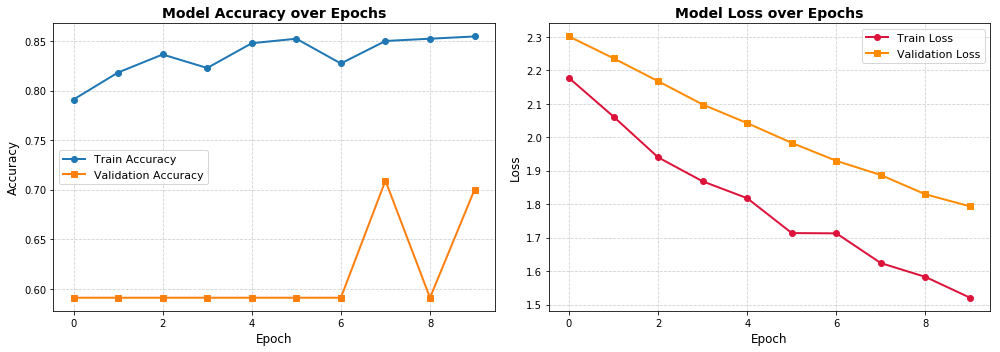

In [10]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Accuracy
ax1.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2, marker='o')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2, marker='s')
ax1.set_title('Model Accuracy over Epochs', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy', fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot Loss
ax2.plot(history.history['loss'], label='Train Loss', linewidth=2, marker='o', color='crimson')
ax2.plot(history.history['val_loss'], label='Validation Loss', linewidth=2, marker='s', color='darkorange')
ax2.set_title('Model Loss over Epochs', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Loss', fontsize=12)
ax2.legend(fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [11]:
model.evaluate(X_val, y_val)

110/110 [==============================] - 8s 74ms/sample - loss: 1.7935 - accuracy: 0.7000 - precision: 0.6633 - recall: 1.0000


[1.7935477256774903, 0.7, 0.6632653, 1.0]

Classification Report:
              precision    recall  f1-score   support

    REAL (0)       1.00      0.27      0.42        45
    FAKE (1)       0.66      1.00      0.80        65

    accuracy                           0.70       110
   macro avg       0.83      0.63      0.61       110
weighted avg       0.80      0.70      0.64       110



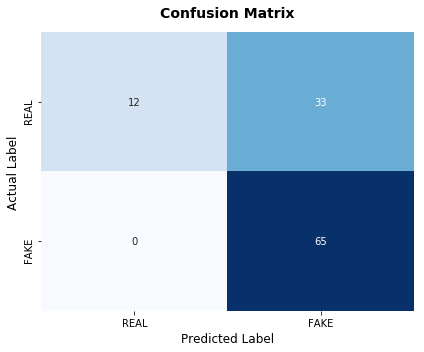

In [12]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Generate probability predictions on the validation set
y_pred_probs = model.predict(X_val)

# 2. Convert probabilities to binary class predictions (threshold at 0.5)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

# 3. Print the Classification Report
print("Classification Report:")
print(classification_report(y_val, y_pred, target_names=['REAL (0)', 'FAKE (1)']))

# 4. Compute and Plot the Confusion Matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['REAL', 'FAKE'],
            yticklabels=['REAL', 'FAKE'])
plt.title('Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.tight_layout()
plt.show()